In [ ]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score as sklearn_silhouette

km = KMeans(n_clusters=3, random_state=42).fit(data)
db = DBSCAN(eps=1.5, min_samples=5).fit(data)
agg = AgglomerativeClustering(n_clusters=3).fit(data)
gmm_model = GaussianMixture(n_components=3, random_state=42).fit(data)

Silhouette scores:
  KMeans         : 0.460
  DBSCAN         : 0.642  (2 clusters, 26 noise)
  Agglomerative  : 0.447
  GMM            : 0.475


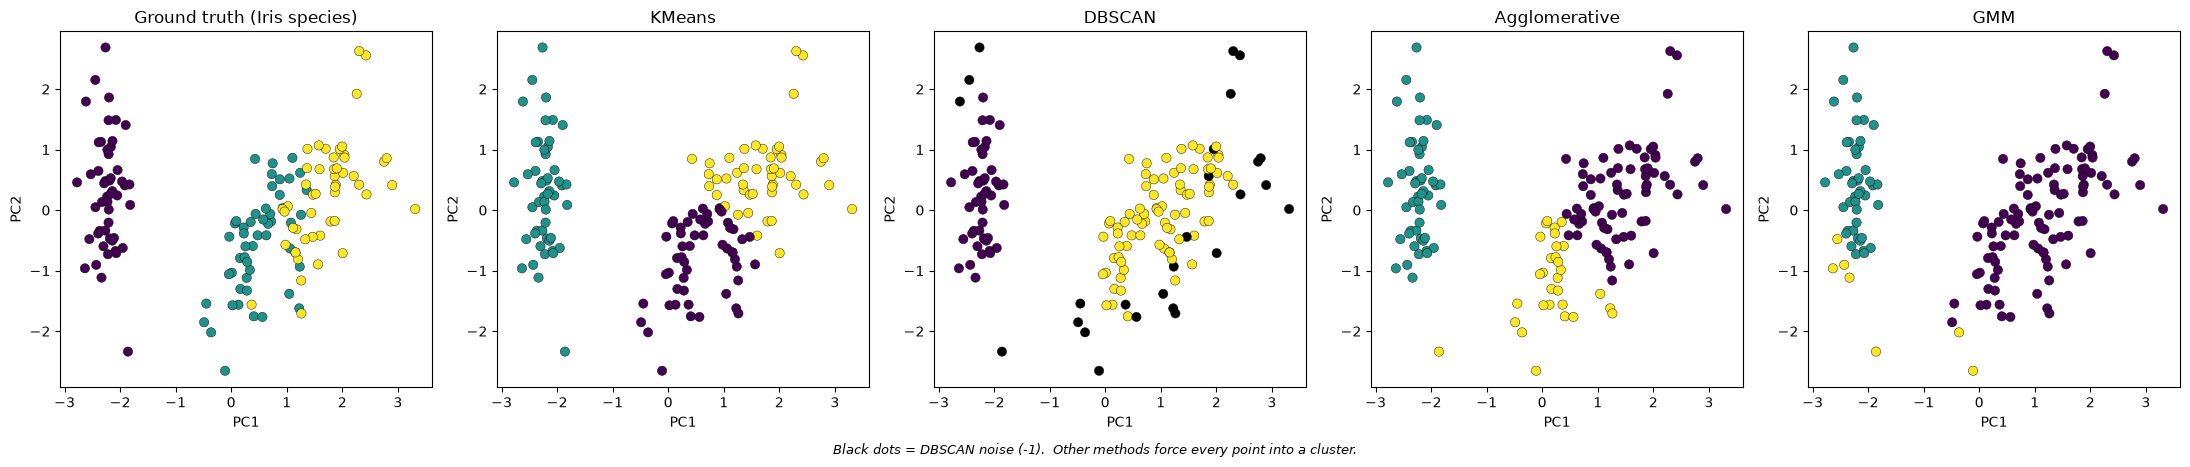

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# ---------- 1. Load + standardize ----------
iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y_true = iris.target

# ---------- 2. Fit all four ----------
km  = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X)
db  = DBSCAN(eps=0.6, min_samples=5).fit(X)
agg = AgglomerativeClustering(n_clusters=3).fit(X)
gmm = GaussianMixture(n_components=3, random_state=42).fit(X)
gmm_labels = gmm.predict(X)

labels = {
    "KMeans": km.labels_,
    "DBSCAN": db.labels_,
    "Agglomerative": agg.labels_,
    "GMM": gmm_labels,
}

# ---------- 3. Silhouette ----------
print("Silhouette scores:")
for name, lab in labels.items():
    uniq = set(lab) - {-1}
    if len(uniq) < 2:
        print(f"  {name:15s}: n/a ({len(uniq)} cluster)")
        continue
    if name == "DBSCAN":
        mask = lab != -1
        s = silhouette_score(X[mask], lab[mask])
        print(f"  {name:15s}: {s:.3f}  ({len(uniq)} clusters, {(lab==-1).sum()} noise)")
    else:
        print(f"  {name:15s}: {silhouette_score(X, lab):.3f}")

# ---------- 4. 2D PCA for plotting ----------
X2 = PCA(n_components=2, random_state=42).fit_transform(X)

# ---------- 5. Colors: cluster 0..k-1 from viridis; noise (-1) = black ----------
def color_for(lab):
    # map each label to a color; -1 → black
    uniq = sorted(set(lab))
    cmap = plt.get_cmap("viridis")
    n_clusters = max([u for u in uniq if u >= 0], default=0) + 1
    colors = []
    for v in lab:
        if v == -1:
            colors.append("black")
        else:
            colors.append(cmap(v / max(n_clusters - 1, 1)))
    return colors

# ---------- 6. Plot ----------
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
titles = ["Ground truth", "KMeans", "DBSCAN", "Agglomerative", "GMM"]

# Ground truth
sc = axes[0].scatter(X2[:, 0], X2[:, 1], c=y_true, cmap="viridis",
                     s=45, edgecolor="k", linewidth=0.3)
axes[0].set_title("Ground truth (Iris species)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

plot_labels = [km.labels_, db.labels_, agg.labels_, gmm_labels]
for ax, name, lab in zip(axes[1:], titles[1:], plot_labels):
    ax.scatter(X2[:, 0], X2[:, 1], c=color_for(lab),
               s=45, edgecolor="k", linewidth=0.3)
    ax.set_title(name)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")

# Note about black dots
fig.text(0.5, -0.02,
         "Black dots = DBSCAN noise (-1).  Other methods force every point into a cluster.",
         ha="center", fontsize=9, style="italic")

plt.tight_layout()
plt.show()

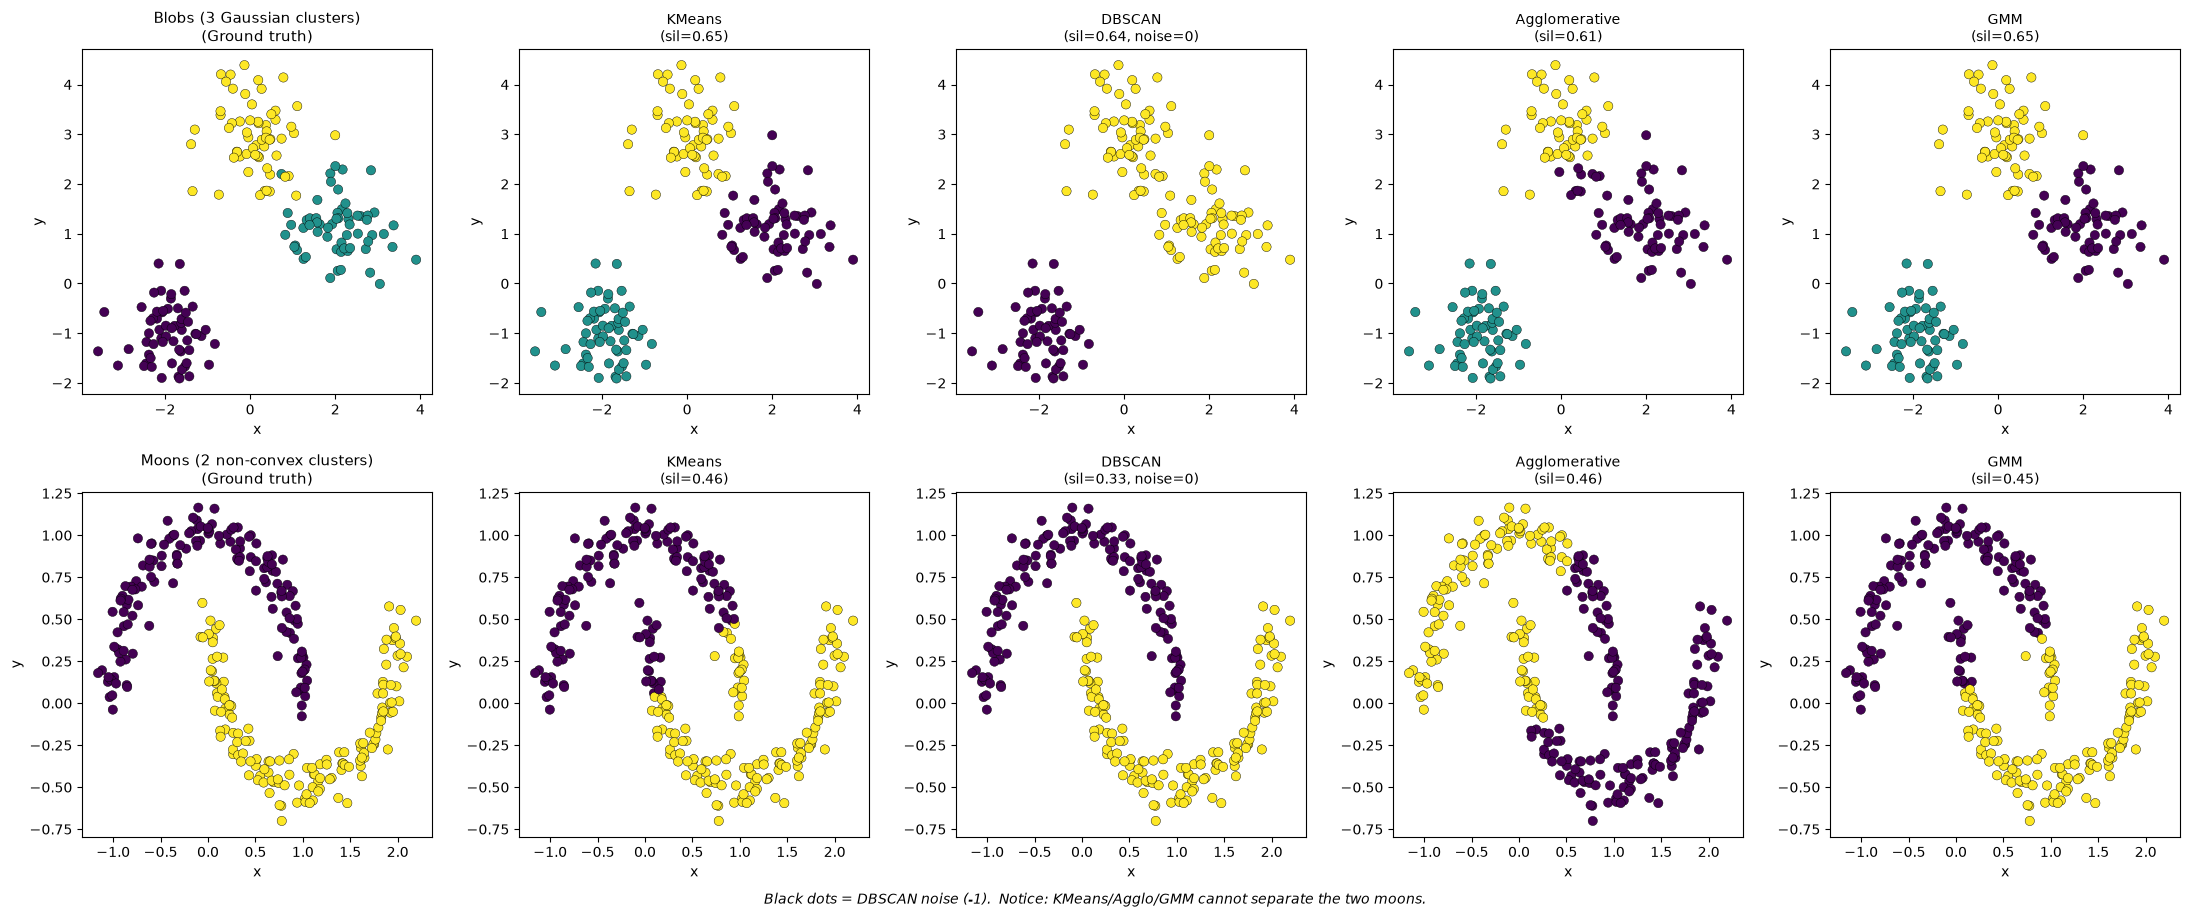

In [3]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score


# ============================================================
# 1. YOUR DATA GENERATORS (unchanged)
# ============================================================
def make_blobs(centers, n_per_cluster=50, spread=0.5, seed=42):
    random.seed(seed)
    data, true_labels = [], []
    for label, (cx, cy) in enumerate(centers):
        for _ in range(n_per_cluster):
            x = cx + random.gauss(0, spread)
            y = cy + random.gauss(0, spread)
            data.append([x, y])
            true_labels.append(label)
    return data, true_labels


def make_moons(n_samples=200, noise=0.1, seed=42):
    random.seed(seed)
    data, labels = [], []
    n_half = n_samples // 2
    for i in range(n_half):
        angle = math.pi * i / n_half
        x = math.cos(angle) + random.gauss(0, noise)
        y = math.sin(angle) + random.gauss(0, noise)
        data.append([x, y]); labels.append(0)
    for i in range(n_half):
        angle = math.pi * i / n_half
        x = 1 - math.cos(angle) + random.gauss(0, noise)
        y = 1 - math.sin(angle) - 0.5 + random.gauss(0, noise)
        data.append([x, y]); labels.append(1)
    return data, labels


# ============================================================
# 2. Build the two datasets
# ============================================================
centers = [(-2, -1), (2, 1), (0, 3)]      # 3 blobs
blob_data, blob_true = make_blobs(centers, n_per_cluster=60, spread=0.6)

moon_data, moon_true = make_moons(n_samples=300, noise=0.08)

datasets = {
    "Blobs (3 Gaussian clusters)": (np.array(blob_data), np.array(blob_true), 3, 0.6),
    "Moons (2 non-convex clusters)": (np.array(moon_data), np.array(moon_true), 2, 0.3),
}


# ============================================================
# 3. Run all four algorithms on one dataset
# ============================================================
def run_all(X, k, db_eps):
    Xs = StandardScaler().fit_transform(X)

    km  = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    db  = DBSCAN(eps=db_eps, min_samples=5).fit(Xs)
    agg = AgglomerativeClustering(n_clusters=k).fit(Xs)
    gmm = GaussianMixture(n_components=k, random_state=42).fit(Xs)

    return {
        "KMeans":        km.labels_,
        "DBSCAN":        db.labels_,
        "Agglomerative": agg.labels_,
        "GMM":           gmm.predict(Xs),
    }


def color_for(lab):
    """cluster 0..k-1 → viridis, noise (-1) → black"""
    cmap = plt.get_cmap("viridis")
    n_clusters = max([v for v in lab if v >= 0], default=0) + 1
    return ["black" if v == -1 else cmap(v / max(n_clusters - 1, 1)) for v in lab]


# ============================================================
# 4. Plot everything — 2 rows (datasets) × 5 cols (truth + 4 methods)
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(22, 9))

for row, (title, (X, y_true, k, db_eps)) in enumerate(datasets.items()):
    # --- Col 0: ground truth ---
    ax = axes[row, 0]
    ax.scatter(X[:, 0], X[:, 1], c=y_true, cmap="viridis",
               s=45, edgecolor="k", linewidth=0.3)
    ax.set_title(f"{title}\n(Ground truth)", fontsize=11)
    ax.set_xlabel("x"); ax.set_ylabel("y")

    # --- Cols 1-4: the four methods ---
    results = run_all(X, k, db_eps)
    for col, (name, lab) in enumerate(results.items(), start=1):
        ax = axes[row, col]
        ax.scatter(X[:, 0], X[:, 1], c=color_for(lab),
                   s=45, edgecolor="k", linewidth=0.3)

        # silhouette for the title
        uniq = set(lab) - {-1}
        if len(uniq) >= 2:
            if name == "DBSCAN":
                mask = lab != -1
                s = silhouette_score(X[mask], lab[mask]) if mask.sum() > 1 else float("nan")
                ax.set_title(f"{name}\n(sil={s:.2f}, noise={(lab==-1).sum()})", fontsize=10)
            else:
                s = silhouette_score(X, lab)
                ax.set_title(f"{name}\n(sil={s:.2f})", fontsize=10)
        else:
            ax.set_title(f"{name}\n(degenerate)", fontsize=10)

        ax.set_xlabel("x"); ax.set_ylabel("y")

fig.text(0.5, -0.01,
         "Black dots = DBSCAN noise (-1).  Notice: KMeans/Agglo/GMM cannot separate the two moons.",
         ha="center", fontsize=10, style="italic")

plt.tight_layout()
plt.show()